# Osmer 신앙 네 차원 분석: 퍼셉트론과 MLP 비교

**학습데이터:** `data/faith_data.xlsx` (100개 가상 진술문)  
**실험데이터:** `data/신앙교육 실습자료_261124.xlsx` (조·발달 단계별 성찰문)  
**실행환경:** VS Code Jupyter Notebook / Python `.venv`

각 셀을 위에서 아래로 실행합니다. **문장당 하나의 차원만 예측**하는 탐색적 모형이며, 결과는 신앙 자체나 신앙 성숙도를 측정하지 않습니다.

## 1. 라이브러리 및 파일 경로

In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

BASE_DIR = Path.cwd()
# VS Code에서 노트북이 프로젝트 폴더가 아닌 곳을 작업 디렉터리로 사용할 경우 보정
if not (BASE_DIR / 'data' / 'faith_data.xlsx').exists():
    raise FileNotFoundError('VS Code에서 faith_osmer_vscode 폴더를 열고 노트북을 실행하세요. data/faith_data.xlsx가 필요합니다.')
DATA_DIR = BASE_DIR / 'data'
RESULTS_DIR = BASE_DIR / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
LABELS = ['신념', '관계', '헌신', '신비']
print('프로젝트 폴더:', BASE_DIR)

프로젝트 폴더: c:\Users\손문\Documents\AI_Research_Lab\faith_osmer_vscode


## 2. 학습 및 실험데이터 확인

In [3]:

%pip install openpyxl


  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel 


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
train = pd.read_excel(DATA_DIR / 'faith_data.xlsx', sheet_name='데이터')
test = pd.read_excel(DATA_DIR / '신앙교육 실습자료_261124.xlsx', sheet_name='Sheet1')
assert {'신앙진술', '차원'}.issubset(train.columns)
assert {'조', '단계', '내용'}.issubset(test.columns)
train = train.dropna(subset=['신앙진술','차원']).copy()
print('학습데이터:', len(train), '개 / 실험데이터:', len(test), '개 기록')
display(train.head())
display(test.head())

학습데이터: 100 개 / 실험데이터: 9 개 기록


,ID,신앙진술,차원
0,F001,나는 하나님이 세상을 창조하셨다는 고백을 신뢰한다.,신념
1,F002,예수님의 부활은 내 신앙에서 중요한 진리이다.,신념
2,F003,성경의 이야기가 오늘의 삶을 이해하는 데 도움을 준다고 믿는다.,신념
3,F004,하나님의 사랑은 인간의 실패보다 크다고 생각한다.,신념
4,F005,나는 삼위일체에 관한 교회의 가르침을 배우고 있다.,신념


,조,단계,내용
0,1,아동기,"교회어린이집을 다니면서 생활, 잘 기억이 나지 않고, 하나님에 대한 명확한 이미지보..."
1,1,청소년,질풍노도의 시기를 겪으며 완전한 단절을 경험했다. 증명하고 싶었다. 공예배말고도 수...
2,1,성인기,다시 하나님과 가까워졌다. 지금까지 따뜻한 이미지가 유지되고 있다. 성인이 되어서는...
3,2,아동기,"절대적인 선과 사랑, 당연하게 받아들이는 하나님 이미지, 신화적인 이미지를 의심없이..."
4,2,청소년,"온전히 독립되기 이전, 열정 가득한 모습. 머리로 알고있는 하나님을 경험, 추상적인..."


## 3. 퍼셉트론의 5겹 교차검증
TF-IDF는 각 훈련 폴드 내부에서 학습되므로 평가 폴드의 정보가 새어 들어가지 않습니다.

In [5]:
def make_perceptron():
    return Pipeline([
        ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(2,4))),
        ('model', Perceptron(max_iter=2000, tol=1e-3, random_state=42))
    ])

X = train['신앙진술'].astype(str)
y = train['차원']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_cv = cross_val_predict(make_perceptron(), X, y, cv=cv)
print('퍼셉트론 교차검증 정확도:', round(accuracy_score(y, y_cv), 3))
print(classification_report(y, y_cv, labels=LABELS, zero_division=0))
cm = pd.DataFrame(confusion_matrix(y, y_cv, labels=LABELS), index=LABELS, columns=LABELS)
display(cm)

퍼셉트론 교차검증 정확도: 0.67
              precision    recall  f1-score   support

          신념       0.63      0.76      0.69        25
          관계       0.70      0.76      0.73        25
          헌신       0.73      0.64      0.68        25
          신비       0.62      0.52      0.57        25

    accuracy                           0.67       100
   macro avg       0.67      0.67      0.67       100
weighted avg       0.67      0.67      0.67       100



,신념,관계,헌신,신비
신념,19,1,2,3
관계,0,19,1,5
헌신,3,6,16,0
신비,8,1,3,13


## 4. 퍼셉트론과 다층 퍼셉트론(MLP) 비교
같은 5개 분할을 사용하여 성능을 비교합니다. 소규모 합성데이터이므로 MLP가 더 우수하다고 가정할 수 없습니다.

In [6]:
models = {
    'Perceptron': Perceptron(max_iter=2000, tol=1e-3, random_state=42),
    'MLP (32,16)': MLPClassifier(hidden_layer_sizes=(32,16), max_iter=1000, random_state=42)
}
comparison_rows = []
for name, classifier in models.items():
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(2,4))),
        ('model', classifier)
    ])
    scores = cross_val_score(pipeline, X, y, cv=cv, scoring='accuracy')
    comparison_rows.append({'모델':name, '평균정확도':scores.mean(), '표준편차':scores.std()})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))

,모델,평균정확도,표준편차
0,Perceptron,0.67,0.068
1,"MLP (32,16)",0.66,0.116


## 5. 전체 학습데이터로 최종 퍼셉트론 학습

In [7]:
model = make_perceptron()
model.fit(X, y)
print('최종 모델 학습 완료')

최종 모델 학습 완료


## 6. 실험데이터를 문장 단위로 나누어 분류
문장부호/줄바꿈 기준의 간단한 분리이므로 연구자 검토가 필요합니다. 한 문장에 여러 차원이 나타나더라도 현재 모형은 하나만 선택합니다.

In [8]:
def split_text(text):
    parts = re.split(r'(?<=[.!?])\s+|\n+', str(text).strip())
    return [part.strip() for part in parts if len(part.strip()) >= 4]

rows = []
for idx, row in test.iterrows():
    group = str(row['조'])
    if not group.endswith('조'):
        group += '조'
    for j, sentence in enumerate(split_text(row['내용']), 1):
        rows.append({'원본행': idx+2, '조':group, '단계':str(row['단계']), '문장번호':j, '문장':sentence})
units = pd.DataFrame(rows)
if units.empty:
    raise ValueError('실험데이터에서 분석할 문장을 찾지 못했습니다.')
units['AI_예측차원'] = model.predict(units['문장'])
scores = model.decision_function(units['문장'])
for i, label in enumerate(model.named_steps['model'].classes_):
    units['판별점수_'+label] = scores[:,i]
print('분석 문장 수:', len(units))
display(units.head(10))

분석 문장 수: 45


,원본행,조,단계,문장번호,문장,AI_예측차원,판별점수_관계,판별점수_신념,판별점수_신비,판별점수_헌신
0,2,1조,아동기,1,"교회어린이집을 다니면서 생활, 잘 기억이 나지 않고, 하나님에 대한 명확한 이미지보...",헌신,-0.201261,-0.268506,-0.440235,0.025976
1,2,1조,아동기,2,모태신앙으로 교회를 다니는 것이 당연했다.,관계,0.037670,-0.349668,-0.039697,-0.097026
2,2,1조,아동기,3,엄마를 따라 교회에 다니면서 엄마가 기도하는 모습을 종종 보게 되었다.,관계,0.388076,-0.211027,-0.534066,-0.056321
3,2,1조,아동기,4,"그때는 엄마가 좋아서 따라다닌 것 같은데,",헌신,-0.068639,-0.133289,-0.051584,0.006261
4,3,1조,청소년,1,질풍노도의 시기를 겪으며 완전한 단절을 경험했다.,신비,0.028623,-0.540995,0.149476,-0.115831
5,3,1조,청소년,2,증명하고 싶었다.,헌신,-0.333773,-0.196677,-0.341562,0.033371
6,3,1조,청소년,3,"공예배말고도 수요예배, 금요예배 등에 참여해야 하는 상황이 되면서 하나님은 질서가 ...",관계,-0.010786,-0.205909,-0.315235,-0.160989
7,3,1조,청소년,4,그러다가 코로나가 터지면서 자연스럽게 교회와 예배로부터 멀어지기도 했다.,관계,0.085868,-0.146672,-0.171556,-0.015842
8,3,1조,청소년,5,청소년기에 들어서면서 겪게 된 학업에 대한 어려움과 친구 관계에 문제가 있을 때마다...,관계,0.308301,-0.333238,-0.486213,-0.177889
9,4,1조,성인기,1,다시 하나님과 가까워졌다.,관계,0.267608,0.008566,-0.398140,-0.149221


## 7. 조별·발달 단계별 빈도와 비율

In [9]:
def distribution(data, group_cols):
    counts = pd.crosstab([data[c] for c in group_cols], data['AI_예측차원'])
    counts = counts.reindex(columns=LABELS, fill_value=0)
    pct = counts.div(counts.sum(axis=1), axis=0).mul(100).round(1)
    return counts.reset_index(), pct.reset_index()

by_group_n, by_group_pct = distribution(units, ['조'])
by_stage_n, by_stage_pct = distribution(units, ['단계'])
by_both_n, by_both_pct = distribution(units, ['조','단계'])
print('조별 비율 (%)')
display(by_group_pct)
print('발달 단계별 비율 (%)')
display(by_stage_pct)

조별 비율 (%)


AI_예측차원,조,신념,관계,헌신,신비
0,1조,5.9,58.8,23.5,11.8
1,2조,0.0,66.7,13.3,20.0
2,3조,0.0,76.9,15.4,7.7


발달 단계별 비율 (%)


AI_예측차원,단계,신념,관계,헌신,신비
0,성인기,5.3,68.4,15.8,10.5
1,아동기,0.0,66.7,25.0,8.3
2,청소년,0.0,64.3,14.3,21.4


## 8. 그래프 출력

C:\Users\손문\AppData\Local\Temp\ipykernel_16400\2957276873.py:10: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\손문\AppData\Local\Temp\ipykernel_16400\2957276873.py:10: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\손문\AppData\Local\Temp\ipykernel_16400\2957276873.py:10: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\손문\AppData\Local\Temp\ipykernel_16400\2957276873.py:10: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\손문\AppData\Local\Temp\ipykernel_16400\2957276873.py:12: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=160)
C:\Users\손문\AppData\Local\Temp\ipykernel_16400\2957276873.py:12: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from fo

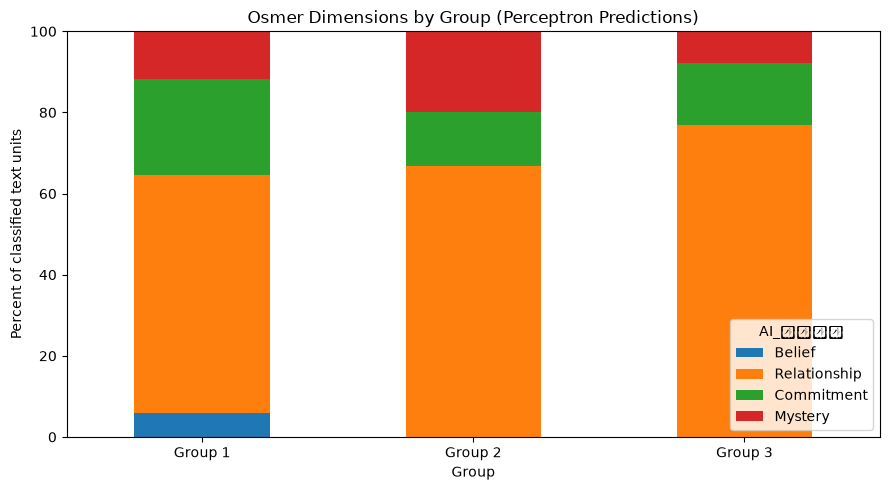

저장: c:\Users\손문\Documents\AI_Research_Lab\faith_osmer_vscode\results\faith_osmer_group_chart.png


In [10]:
plot_df = by_group_pct.set_index('조')[LABELS].rename(columns={
    '신념':'Belief', '관계':'Relationship', '헌신':'Commitment', '신비':'Mystery'
})
plot_df.index = ['Group ' + str(v).replace('조','') for v in plot_df.index]
ax = plot_df.plot(kind='bar', stacked=True, figsize=(9,5), ylim=(0,100))
ax.set_title('Osmer Dimensions by Group (Perceptron Predictions)')
ax.set_ylabel('Percent of classified text units')
ax.set_xlabel('Group')
plt.xticks(rotation=0)
plt.tight_layout()
chart_path = RESULTS_DIR / 'faith_osmer_group_chart.png'
plt.savefig(chart_path, dpi=160)
plt.show()
print('저장:', chart_path)

## 9. 엑셀 결과 저장

In [11]:
output = RESULTS_DIR / 'faith_osmer_analysis_results.xlsx'
with pd.ExcelWriter(output, engine='openpyxl') as writer:
    units.to_excel(writer, sheet_name='문장별_AI분류', index=False)
    by_group_pct.to_excel(writer, sheet_name='조별_비율', index=False)
    by_group_n.to_excel(writer, sheet_name='조별_빈도', index=False)
    by_stage_pct.to_excel(writer, sheet_name='발달단계별_비율', index=False)
    by_stage_n.to_excel(writer, sheet_name='발달단계별_빈도', index=False)
    by_both_pct.to_excel(writer, sheet_name='조_단계별_비율', index=False)
    by_both_n.to_excel(writer, sheet_name='조_단계별_빈도', index=False)
    cm.to_excel(writer, sheet_name='학습교차검증_혼동행렬')
    comparison.to_excel(writer, sheet_name='퍼셉트론_MLP비교', index=False)
print('결과 저장 완료:', output)

결과 저장 완료: c:\Users\손문\Documents\AI_Research_Lab\faith_osmer_vscode\results\faith_osmer_analysis_results.xlsx


## 10. 해석과 연구윤리 점검

- 학습데이터 100개는 **가상 진술문**입니다. 교차검증 정확도는 실제 대학원생 자료에 대한 정확도가 아닙니다.
- 문장별 분류는 **단일 레이블**이며 네 차원의 실제 구성비를 뜻하지 않습니다.
- 연구자가 문장별 정답을 독립적으로 코딩한 뒤 모델과 비교해야 실제 자료에서의 분류 타당도를 평가할 수 있습니다.
- 조별 기록을 문장으로 나누었다고 독립 표본 수가 그만큼 증가하는 것은 아닙니다.
- 개인의 신앙 경험을 포함한 원문을 외부에 공유할 때는 동의 및 비식별화 여부를 확인하세요.